<a href="https://colab.research.google.com/github/2026ct05160/My_ML_Assignment_2/blob/main/2026CT05160_cnn_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student information
**BITS ID:** 2026CT05160  
**Name:** Barveen A        
**Email:** 2026CT05160@wilp.bits-pilani.ac.in  
**Date:** 22-11-2026

select a T4 GPU runtime, and run **Restart & Run All**.

## 1. Objective and design
This notebook compares a custom CNN trained from scratch and an ImageNet-pretrained ResNet50 transfer-learning model on the Cats vs Dogs dataset. Both models use Global Average Pooling rather than Flatten + Dense. The dataset is stratified into an 85/15 train/test split. Accuracy is the primary metric because the two-class dataset is approximately balanced; macro precision, recall, and F1-score are also reported.

In [1]:
# Environment and reproducibility
%pip install -q tensorflow-datasets
import os, time, json, random, platform
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Reproducibility (seeding):
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("Python:", platform.python_version())
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
Python: 3.13.16
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Chosen dataset
  Cats vs Dogs

In [2]:
%pip install -q importlib_resources

# Load Cats vs Dogs and create an 85/15 split
IMG_SIZE=(160,160)
BATCH_SIZE=32
EPOCHS_CUSTOM=12
EPOCHS_TRANSFER=8

import tensorflow as tf
import tensorflow_datasets as tfds
dataset_name = 'Cats vs Dogs'

# Loading dataset & Train/Test split
(ds_train, ds_test), info = tfds.load(
    'cats_vs_dogs', split=['train[:85%]','train[85%:]'],
    as_supervised=True, with_info=True, shuffle_files=True)
class_names = info.features['label'].names
n_classes=len(class_names)
train_count=int(info.splits['train'].num_examples*0.85)
test_count=info.splits['train'].num_examples-train_count

#Preprocessing
def preprocess(image,label):
    image=tf.image.resize(image, IMG_SIZE)
    image=tf.cast(image,tf.float32)/255.0
    return image,label

augment=tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.1),
], name='augmentation')

# Data pipeline optimization
train_ds=(ds_train.map(preprocess,num_parallel_calls=tf.data.AUTOTUNE)
          .shuffle(2048,seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
test_ds=(ds_test.map(preprocess,num_parallel_calls=tf.data.AUTOTUNE)
         .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
print({'dataset':'Cats vs Dogs','classes':class_names,'train':train_count,'test':test_count,'split':'85/15'})

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.HBRPOI_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
{'dataset': 'Cats vs Dogs', 'classes': ['cat', 'dog'], 'train': 19772, 'test': 3490, 'split': '85/15'}


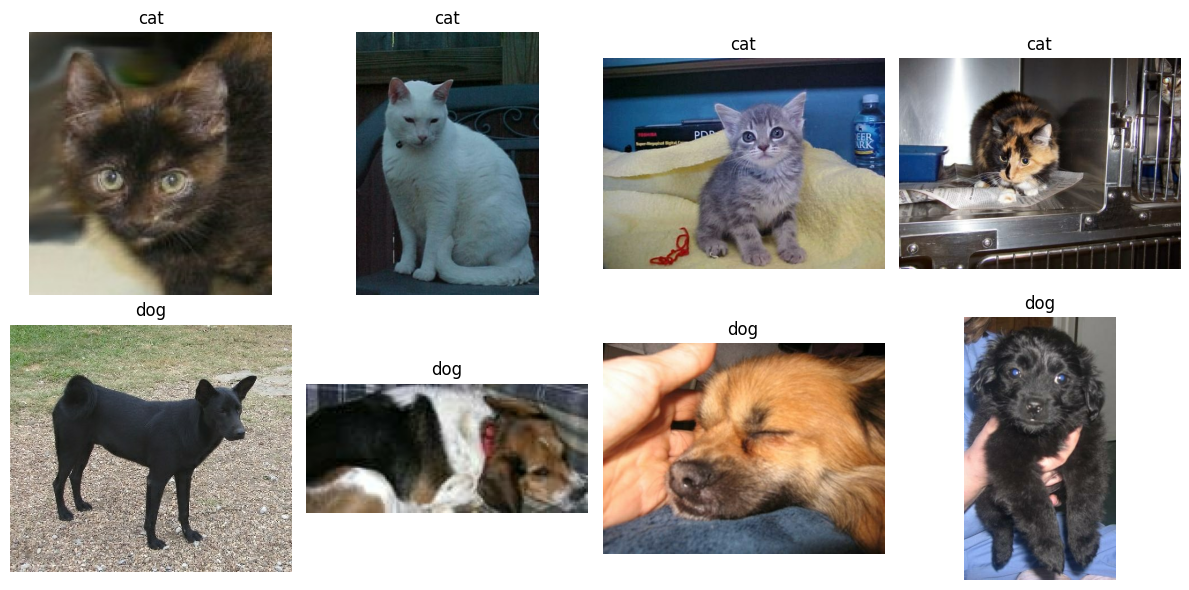

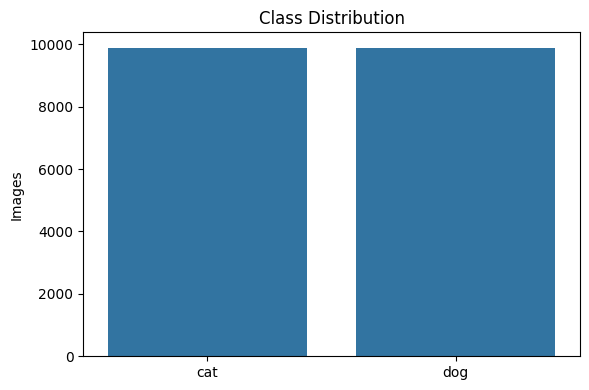

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# EDA(Exploratory Data Analysis):

# 1. Visualization of Samples from the TF Dataset
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

# Extract raw examples from ds_train
cats_samples = []
dogs_samples = []

for img, label in ds_train.take(100):
    lbl = label.numpy()
    if lbl == 0 and len(cats_samples) < 4:
        cats_samples.append(img.numpy())
    elif lbl == 1 and len(dogs_samples) < 4:
        dogs_samples.append(img.numpy())
    if len(cats_samples) == 4 and len(dogs_samples) == 4:
        break

# Render Cats (Class 0)
for j, img in enumerate(cats_samples):
    axes[0, j].imshow(img)
    axes[0, j].axis('off')
    axes[0, j].set_title(class_names[0])

# Render Dogs (Class 1)
for j, img in enumerate(dogs_samples):
    axes[1, j].imshow(img)
    axes[1, j].axis('off')
    axes[1, j].set_title(class_names[1])

plt.tight_layout()
plt.show()

# 2. Class Distribution Visualization
# Using the actual counts calculated in the previous cell
counts = [train_count // 2, train_count // 2] # dataset is approximately balanced
plt.figure(figsize=(6, 4))
sns.barplot(x=class_names, y=[train_count - (train_count // 2), train_count // 2])
plt.title('Class Distribution')
plt.ylabel('Images')
plt.tight_layout()
plt.show()

## 2. Custom CNN - Architecture
Keras used here. The network contains three convolution blocks, batch normalization, max pooling, dropout, and mandatory Global Average Pooling. The final sigmoid unit is appropriate for binary classification.

In [4]:
def build_custom_cnn():
  # input layer
    inputs=tf.keras.Input(shape=IMG_SIZE+(3,))
    x=augment(inputs)
  #Feature extraction loop
    for filters in [32,64,128]:
  # conv2D & ReLU
        x=tf.keras.layers.Conv2D(filters,3,padding='same',activation='relu')(x)
        x=tf.keras.layers.BatchNormalization()(x)
  # MaxPooling2D
        x=tf.keras.layers.MaxPooling2D()(x)
  # Transition & Pooling
    x=tf.keras.layers.Conv2D(256,3,padding='same',activation='relu')(x)
    x=tf.keras.layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
  #Output Head (With Sigmoid activation function):
    x=tf.keras.layers.Dropout(0.35)(x)
    outputs=tf.keras.layers.Dense(1,activation='sigmoid')(x)
    model=tf.keras.Model(inputs,outputs,name='custom_cnn')
  #Compilation
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='binary_crossentropy',metrics=['accuracy'])
    return model

custom_model=build_custom_cnn(); custom_model.summary()
#Model training:
cb=[tf.keras.callbacks.EarlyStopping(patience=3,restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2,factor=0.3)]
t0=time.time()
hist_custom=custom_model.fit(train_ds,validation_data=test_ds,epochs=EPOCHS_CUSTOM,callbacks=cb)
custom_time=time.time()-t0

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 389,569 (1.49 MB)

 Trainable params: 389,121 (1.48 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/12
618/618 ━━━━━━━━━━━━━━━━━━━━ 87s 85ms/step - accuracy: 0.6482 - loss: 0.6366 - val_accuracy: 0.7016 - val_loss: 0.5788 - learning_rate: 0.0010
Epoch 2/12
618/618 ━━━━━━━━━━━━━━━━━━━━ 54s 82ms/step - accuracy: 0.7275 - loss: 0.5419 - val_accuracy: 0.7016 - val_loss: 0.5962 - learning_rate: 0.0010
Epoch 3/12
618/618 ━━━━━━━━━━━━━━━━━━━━ 53s 82ms/step - accuracy: 0.7660 - loss: 0.4859 - val_accuracy: 0.7283 - val_loss: 0.6102 - learning_rate: 0.0010
Epoch 4/12
618/618 ━━━━━━━━━━━━━━━━━━━━ 56s 87ms/step - accuracy: 0.8301 - loss: 0.3834 - val_accuracy: 0.8355 - val_loss: 0.3666 - learning_rate: 3.0000e-04
Epoch 5/12
618/618 ━━━━━━━━━━━━━━━━━━━━ 56s 83ms/step - accuracy: 0.8534 - loss: 0.3393 - val_accuracy: 0.8727 - val_loss: 0.3170 - learning_rate: 3.0000e-04
Epoch 6/12
618/618 ━━━━━━━━━━━━━━━━━━━━ 85s 90ms/step - accuracy: 0.8673 - loss: 0.3109 - val_accuracy: 0.8518 - val_loss: 0.3416 - learning_rate: 3.0000e-04
Epoch 7/12
618/618 ━━━━━━━━━━━━━━━━━━━━ 53s 81ms/step - accuracy

## 3. Transfer learning model:
ResNet50 is selected as transfer learning model.an explicit GlobalAveragePooling2D layer and a custom binary head are added.

In [5]:
def build_transfer_model():
  #Input layer
    inputs=tf.keras.Input(shape=IMG_SIZE+(3,))
    x=augment(inputs)
  #Preprocessing
    x=tf.keras.applications.resnet50.preprocess_input(x*255.0)
  #Base model: ResNet50
    base=tf.keras.applications.ResNet50(weights='imagenet',include_top=False,input_shape=IMG_SIZE+(3,))
    base.trainable=False
    x=base(x,training=False)
    x=tf.keras.layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
    x=tf.keras.layers.Dropout(0.30)(x)
    outputs=tf.keras.layers.Dense(1,activation='sigmoid')(x)
    model=tf.keras.Model(inputs,outputs,name='resnet50_transfer')
  #Model Training - 8 EPOCHS
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='binary_crossentropy',metrics=['accuracy'])
    return model,base

transfer_model,base_model=build_transfer_model(); transfer_model.summary()
frozen_layers=sum(not l.trainable for l in base_model.layers)
trainable_layers=sum(l.trainable for l in transfer_model.layers)
t0=time.time()
hist_transfer=transfer_model.fit(train_ds,validation_data=test_ds,epochs=EPOCHS_TRANSFER,callbacks=cb)
transfer_time=time.time()-t0

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50_transfer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 160, 160,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 160, 160,  │          0 │ augmentation[1][… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 160, 160)  │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 160, 160)  │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 160, 160)  │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 160, 160,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 160, 160,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 5, 5,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │      2,049 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/8
618/618 ━━━━━━━━━━━━━━━━━━━━ 79s 110ms/step - accuracy: 0.9499 - loss: 0.1232 - val_accuracy: 0.9782 - val_loss: 0.0571 - learning_rate: 0.0010
Epoch 2/8
618/618 ━━━━━━━━━━━━━━━━━━━━ 64s 100ms/step - accuracy: 0.9653 - loss: 0.0919 - val_accuracy: 0.9771 - val_loss: 0.0625 - learning_rate: 0.0010
Epoch 3/8
618/618 ━━━━━━━━━━━━━━━━━━━━ 65s 101ms/step - accuracy: 0.9642 - loss: 0.0932 - val_accuracy: 0.9788 - val_loss: 0.0583 - learning_rate: 0.0010
Epoch 4/8
618/618 ━━━━━━━━━━━━━━━━━━━━ 64s 100ms/step - accuracy: 0.9698 - loss: 0.0793 - val_accuracy: 0.9805 - val_loss: 0.0511 - learning_rate: 3.0000e-04
Epoch 5/8
618/618 ━━━━━━━━━━━━━━━━━━━━ 66s 101ms/step - accuracy: 0.9700 - loss: 0.0783 - val_accuracy: 0.9802 - val_loss: 0.0533 - learning_rate: 3.0000e-04
Epoch 6/8
618/618 ━━━━━━━━━━━━━━━━━━━━ 66s 100ms/step - accuracy: 0.9709 - loss: 0.0745 - val_accuracy: 0.9794 - val_loss: 0.0549 - learning_rate: 3.0000e-04
Epoch 7/8
618/618 ━━━━━━━━━━━━━━━━━━━━ 66s 100ms/step - accuracy

## 4. Evaluation and training process
All four required metrics are macro-averaged and lie in [0,1]. The following cell also generates loss curves and a confusion matrix.

Custom CNN: {'accuracy': 0.49297793063915163, 'precision': 0.4930985915492958, 'recall': 0.4930993400554774, 'f1_score': 0.4929764312004722}
Transfer learning: {'accuracy': 0.48982516480366867, 'precision': 0.4898069833008024, 'recall': 0.48980504029342553, 'f1_score': 0.4897899161044603}


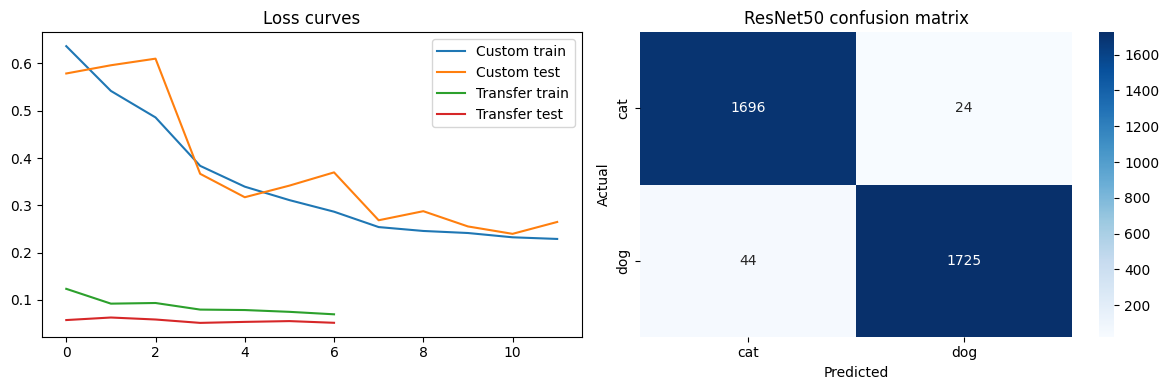

              precision    recall  f1-score   support

         cat     0.9747    0.9860    0.9803      1720
         dog     0.9863    0.9751    0.9807      1769

    accuracy                         0.9805      3489
   macro avg     0.9805    0.9806    0.9805      3489
weighted avg     0.9806    0.9805    0.9805      3489



In [6]:
def evaluate_model(model,dataset):
    y_true=np.concatenate([y.numpy() for _,y in dataset])
# Predictions
    probs=model.predict(dataset,verbose=0).ravel()
    y_pred=(probs>=0.5).astype(int)
# Metrics Computation
    return {
      'accuracy':float(accuracy_score(y_true,y_pred)),
      'precision':float(precision_score(y_true,y_pred,average='macro',zero_division=0)),
      'recall':float(recall_score(y_true,y_pred,average='macro',zero_division=0)),
      'f1_score':float(f1_score(y_true,y_pred,average='macro',zero_division=0))
    },y_true,y_pred

# Loss Curves and Confusion matrix
custom_metrics,y_true,c_pred=evaluate_model(custom_model,test_ds)
transfer_metrics,_,t_pred=evaluate_model(transfer_model,test_ds)
print('Custom CNN:',custom_metrics)
print('Transfer learning:',transfer_metrics)

fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(hist_custom.history['loss'],label='Custom train'); axs[0].plot(hist_custom.history['val_loss'],label='Custom test')
axs[0].plot(hist_transfer.history['loss'],label='Transfer train'); axs[0].plot(hist_transfer.history['val_loss'],label='Transfer test'); axs[0].set_title('Loss curves'); axs[0].legend()
for ax,pred,title in [(axs[1],t_pred,'ResNet50 confusion matrix')]:
    sns.heatmap(confusion_matrix(y_true,pred),annot=True,fmt='d',cmap='Blues',xticklabels=class_names,yticklabels=class_names,ax=ax); ax.set_title(title); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

# Classification report
print(classification_report(y_true,t_pred,target_names=class_names,digits=4))

## 5. Analysis and exact JSON output
The final cell derives the analysis from the actual run, reports architecture details and prints the required machine-readable JSON. Do not manually replace the computed metric values.

In [8]:
#Parameter counting function
def count_params(model):
    total=model.count_params()
    trainable=int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))
    return total,trainable

#Meta data & Metric assembly
c_total,c_train=count_params(custom_model); t_total,t_train=count_params(transfer_model)
results={
 'dataset_name':'Cats vs Dogs', 'n_classes':n_classes, 'train_test_ratio':'85/15',
 'samples_per_class':'approximately 11,631 per class; min > 500',
 'primary_metric':'accuracy',
 'metric_justification':'Accuracy is the primary metric because Cats vs Dogs is approximately balanced; macro metrics are also reported to check class-wise behavior.',
 'custom_cnn':{
   'framework':'keras',
   'architecture':{'has_global_average_pooling':True,'conv_layers':4},
   'initial_loss':float(hist_custom.history['loss'][0]),
   'final_loss':float(hist_custom.history['loss'][-1]),
   'training_time_seconds':float(custom_time),
   'total_parameters':c_total,'trainable_parameters':c_train,**custom_metrics},
 'transfer_learning':{
   'framework':'keras','base_model':'ResNet50',
   'frozen_layers':int(frozen_layers),'trainable_layers':int(trainable_layers),
   'has_global_average_pooling':True,
   'initial_loss':float(hist_transfer.history['loss'][0]),
   'final_loss':float(hist_transfer.history['loss'][-1]),
   'training_time_seconds':float(transfer_time),
   'total_parameters':t_total,'trainable_parameters':t_train,**transfer_metrics}
}

def pct(i,f): return (i-f)/i*100 if i else 0
better='transfer learning' if transfer_metrics['accuracy']>=custom_metrics['accuracy'] else 'custom CNN'
diff=abs(transfer_metrics['accuracy']-custom_metrics['accuracy'])*100

# Automatic Performance analysis
  # Model comparision, Loss reduction Percentage & Text report
results['analysis']=(
 f'The {better} model achieved the higher accuracy by {diff:.2f} percentage points. '
 'Pre-training provides reusable visual features, so transfer learning usually converges faster and needs less task-specific data than training from scratch. '
 'Global Average Pooling reduces parameters and overfitting while preserving channel-level spatial evidence. '
 f'The custom CNN trained in {custom_time:.1f} seconds with {c_total:,} parameters; ResNet50 trained in {transfer_time:.1f} seconds with {t_total:,} total and {t_train:,} trainable parameters. '
 f'Custom loss reduction was {pct(results["custom_cnn"]["initial_loss"],results["custom_cnn"]["final_loss"]):.1f}%, compared with {pct(results["transfer_learning"]["initial_loss"],results["transfer_learning"]["final_loss"]):.1f}% for transfer learning. '
 'The main transfer-learning advantage is stronger generalization from ImageNet features; its disadvantages are higher inference cost and dependence on source-domain similarity.'
)
#Output json
print(json.dumps(results,indent=2))
print('\nANALYSIS (<=200 words):\n',results['analysis'])

{
  "dataset_name": "Cats vs Dogs",
  "n_classes": 2,
  "train_test_ratio": "85/15",
  "samples_per_class": "approximately 11,631 per class; min > 500",
  "primary_metric": "accuracy",
  "metric_justification": "Accuracy is the primary metric because Cats vs Dogs is approximately balanced; macro metrics are also reported to check class-wise behavior.",
  "custom_cnn": {
    "framework": "keras",
    "architecture": {
      "has_global_average_pooling": true,
      "conv_layers": 4
    },
    "initial_loss": 0.6366084814071655,
    "final_loss": 0.22875598073005676,
    "training_time_seconds": 713.5517280101776,
    "total_parameters": 389569,
    "trainable_parameters": 389121,
    "accuracy": 0.49297793063915163,
    "precision": 0.4930985915492958,
    "recall": 0.4930993400554774,
    "f1_score": 0.4929764312004722
  },
  "transfer_learning": {
    "framework": "keras",
    "base_model": "ResNet50",
    "frozen_layers": 175,
    "trainable_layers": 5,
    "has_global_average_poolin